In [1]:
import logging
logging.captureWarnings(True)

In [2]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

sns.set_theme(context = 'notebook',
              style = 'darkgrid',
              palette = 'deep',
              font = 'sans-serif',
              font_scale = 1,
              color_codes = True,
              rc = None)

from tqdm import tqdm

In [3]:
from multifractal_networks.mfng import MultifractalNetworkGenerator
from multifractal_networks.mfnf import MultifractalNetworkFitter

# Graph import

In [4]:
def parse_network_data(file_path):
    """
    Parse the mixed-format network data file into a pandas DataFrame.

    Args:
        file_path (str): Path to the input file.

    Returns:
        pd.DataFrame: A DataFrame with columns ['Source', 'Target', 'Weight', 'Timestamp'].
    """
    def parse_mixed_format(row):
        parts = row.strip().split('\t')
        if len(parts) >= 3:
            last_part = parts[-1].split()  # Split the last part to extract the timestamp
            if len(last_part) == 2:
                parts[-1], timestamp = last_part  # Adjust the last column and extract the timestamp
                return parts + [timestamp]
        return None

    # Read the raw content and parse the rows
    with open(file_path, 'r') as file:
        raw_content = file.readlines()

    parsed_data = [
        parse_mixed_format(line)
        for line in raw_content
        if not line.startswith('%') and parse_mixed_format(line) is not None
    ]

    # Create a DataFrame and convert columns to appropriate types
    columns = ['Source', 'Target', 'Weight', 'Timestamp']
    dataframe = pd.DataFrame(parsed_data, columns=columns).astype(int)

    dataframe['Datetime'] = pd.to_datetime(dataframe['Timestamp'], unit='s')

    return dataframe

def create_cumulative_graph(dataframe, timestamp_index):
    """
    Create a cumulative NetworkX graph up to a given timestamp index.

    Args:
        dataframe (pd.DataFrame): A DataFrame containing network data with 'Timestamp'.
        timestamp_index (int): Index (0-based) corresponding to the desired timestamp.

    Returns:
        networkx.Graph: A cumulative graph up to the specified timestamp.
    """
    # Ensure the DataFrame is sorted by timestamp
    dataframe = dataframe.sort_values('Timestamp')

    # Get unique timestamps and validate the index
    unique_timestamps = sorted(dataframe['Timestamp'].unique())
    if timestamp_index < 0 or timestamp_index >= len(unique_timestamps):
        raise ValueError(f"Timestamp index must be between 0 and {len(unique_timestamps) - 1}.")

    # Filter the data up to the specified timestamp
    cutoff_timestamp = unique_timestamps[timestamp_index]
    cumulative_data = dataframe[dataframe['Timestamp'] <= cutoff_timestamp]

    # Create the graph
    G = nx.Graph()
    for _, row in cumulative_data.iterrows():
        if row['Source'] != row['Target']:  # Ignore self-loops
            G.add_edge(row['Source'], row['Target'])

    return G

In [5]:
network_pandas = parse_network_data('test_networks/out.dblp-cite')

In [6]:
network_pandas

,Source,Target,Weight,Timestamp,Datetime
0,1,2,1,820454461,1996-01-01 00:01:01
1,1,3,1,820454461,1996-01-01 00:01:01
2,10001,10002,1,915148861,1999-01-01 00:01:01
3,10001,10003,1,915148861,1999-01-01 00:01:01
4,10001,10004,1,915148861,1999-01-01 00:01:01
...,...,...,...,...,...
49754,9996,8019,1,725846461,1993-01-01 00:01:01
49755,9996,880,1,725846461,1993-01-01 00:01:01
49756,9996,954,1,725846461,1993-01-01 00:01:01
49757,9996,9993,1,725846461,1993-01-01 00:01:01


## Explore the network over time

In [7]:
len(network_pandas['Timestamp'].unique())

30

In [8]:
nodes = []
edges = []
avg_degrees = []
for i in tqdm(range(len(network_pandas['Timestamp'].unique()))):
    g = create_cumulative_graph(network_pandas, i)
    node = g.number_of_nodes()
    edge = g.number_of_edges()
    avg_degree = 2 * edge / node
    nodes.append(node)
    edges.append(edge)
    avg_degrees.append(avg_degree)

100%|██████████| 30/30 [00:24<00:00,  1.23it/s]


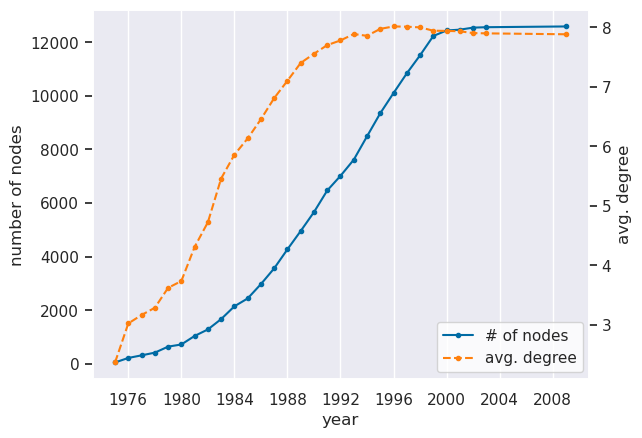

In [9]:
times = sorted(network_pandas['Datetime'].unique())
fig, ax = plt.subplots()
ax.plot(times,nodes,color='#006BA4',label='# of nodes',marker='.')
ax.set_xlabel('year')
ax.set_ylabel('number of nodes')
ax2 = ax.twinx()
ax2.plot(times,avg_degrees,color='#FF800E',label='avg. degree',marker='.',linestyle='--')
ax2.set_ylabel('avg. degree')
ax.grid(False)
ax2.grid(False)
fig.legend(loc=(0.68,0.15),facecolor='white')
ax.xaxis.grid(True)
plt.savefig('./figures/dblp_cite_growth_over_time.pdf', dpi = 1000, bbox_inches='tight')
plt.show()

In [10]:
G_start = create_cumulative_graph(network_pandas, 2)

In [11]:
G = G_start

In [12]:
len(G)

314

In [13]:
2 * G.number_of_edges() / G.number_of_nodes()

3.1656050955414012

In [51]:
for m_size in [2,3,5,6,7]:
    print(m_size,' k_max: ',int(np.log(len(G))/(np.log(m_size)))+1)

2  k_max:  9
3  k_max:  6
5  k_max:  4
6  k_max:  4
7  k_max:  3


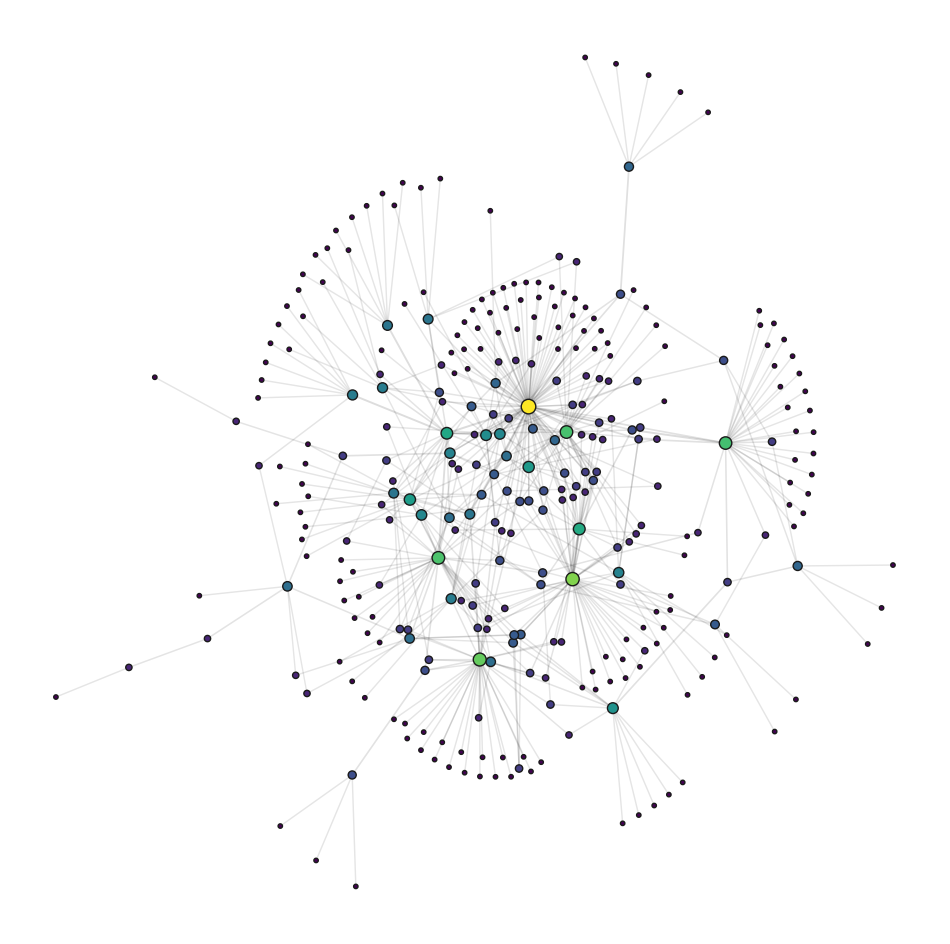

In [16]:
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize, LogNorm

# Keep only the largest connected component
largest_cc = max(nx.connected_components(G), key=len)
G_largest = G.subgraph(largest_cc).copy()

# Sort nodes by degree (ascending), so high-degree nodes are processed last
sorted_nodes = sorted(G_largest.nodes(), key=lambda x: G_largest.degree[x], reverse=True)

# Relabel the graph nodes to ensure sorted order is reflected
mapping = {node: i for i, node in enumerate(sorted_nodes)}
G_largest = nx.relabel_nodes(G_largest, mapping)

# Recalculate node degrees (now sorted)
degree = dict(G_largest.degree())
nx.set_node_attributes(G_largest, degree, 'degree')

# Node size based on degree (logarithmic scaling)
degrees = np.array(list(degree.values()))
degrees += 1  # Avoid log(0) by shifting values
node_sizes = 10 + 100 * (np.log(degrees) - np.log(degrees.min())) / (
    np.log(degrees.max()) - np.log(degrees.min())
)

# Node color based on degree (logarithmic scaling)
cmap = plt.cm.viridis
node_colors = cmap((np.log(degrees) - np.log(degrees.min())) / (np.log(degrees.max()) - np.log(degrees.min())))

# Calculate edge betweenness centrality (for edge width and alpha)
edge_betweenness = nx.edge_betweenness_centrality(G_largest)
edge_widths = [1 + 7 * edge_betweenness[edge] for edge in G_largest.edges()]  # Scale edge widths for visibility
edge_alphas = [0.1 + 0.6 * edge_betweenness[edge] for edge in G_largest.edges()]  # Scale alpha from 0.1 to 1.0

# Positioning nodes using a force-directed layout
pos = nx.kamada_kawai_layout(G_largest)

# Plot the network
plt.figure(figsize=(12, 12))
# Draw edges with scaled widths and alphas
for edge, width, alpha in zip(G_largest.edges(), edge_widths, edge_alphas):
    nx.draw_networkx_edges(
        G_largest,
        pos,
        edgelist=[edge],
        width=width,
        alpha=alpha,
        edge_color="black",
    )

# Draw nodes with size and color mapped to attributes
nx.draw_networkx_nodes(
    G_largest,
    pos,
    node_size=node_sizes,
    node_color=node_colors,
    cmap=cmap,
    edgecolors='k',  # Add a border to nodes for clarity
)

# Remove labels and title for a cleaner plot
plt.gca().set_facecolor("black")

# Hide axes for cleaner visualization
plt.axis('off')
plt.savefig('./figures/dblp_cite_314_nodes_layout.pdf', dpi = 1000, bbox_inches='tight')
plt.show()

# Init Fitter

In [17]:
mfnf = MultifractalNetworkFitter(
    G,                                   
    motifs = [
        {'name': 'four_chain', 'matrix': np.array([[0, 1, 0, 0],[1, 0, 1, 0],[0, 1, 0, 1],[0, 0, 1, 0]])},
        {'name': 'three_loop_out', 'matrix': np.array([[0, 1, 1, 1],[1, 0, 1, 0],[1, 1, 0, 0],[1, 0, 0, 0]])},
        {'name': 'four_loop', 'matrix': np.array([[0, 1, 0, 1],[1, 0, 1, 0],[0, 1, 0, 1],[1, 0, 1, 0]])},
        {'name': 'four_semi_clique', 'matrix': np.array([[0, 1, 1, 1],[1, 0, 0, 1],[1, 0, 0, 1],[1, 1, 1, 0]])},
    ],
    sampling_ratios = {
        3: 0.01,
        4: 0.0001
    },
    motif_analyzer_args = {'exact': True, 'bootstrap_iters': None, 'ci': None},
    population_size = 100,
    weights = {
        'rho':9,
        'deg_nn':9,
        'motifs':1,
        'edge':9
    }
)

Measuring graph properties...
Degree distribution...
Degree correlations...
Motifs...
Checking compatibility with 4 user-provided motifs.
Adding custom motif 'four_chain'.
Adding custom motif 'three_loop_out'.
Adding custom motif 'four_loop'.
Adding custom motif 'four_semi_clique'.
Counting motifs of size 3... grab a tea or watch a movie, this might take a while.
Motif counting finished in 0:00:00.024336
Counting motifs of size 4... grab a tea or watch a movie, this might take a while.
Motif counting finished in 0:00:00.362744


In [18]:
mfnf.motifs

[{'name': 'edge',
  'matrix': array([[0, 1],
         [1, 0]]),
  'size': 2,
  'count': 497},
 {'name': 'wedge',
  'matrix': array([[0, 1, 1],
         [1, 0, 0],
         [1, 0, 0]]),
  'size': 3,
  'count': 8774},
 {'name': 'triangle',
  'matrix': array([[0, 1, 1],
         [1, 0, 1],
         [1, 1, 0]]),
  'size': 3,
  'count': 63},
 {'name': 'three_star',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 0, 0],
         [1, 0, 0, 0],
         [1, 0, 0, 0]]),
  'size': 4,
  'count': 168969},
 {'name': 'four_clique',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 1, 1],
         [1, 1, 0, 1],
         [1, 1, 1, 0]]),
  'size': 4,
  'count': 0},
 {'name': 'four_chain',
  'matrix': array([[0, 1, 0, 0],
         [1, 0, 1, 0],
         [0, 1, 0, 1],
         [0, 0, 1, 0]]),
  'size': 4,
  'count': 21757},
 {'name': 'three_loop_out',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 1, 0],
         [1, 1, 0, 0],
         [1, 0, 0, 0]]),
  'size': 4,
  'count': 4015},
 {'name': 'four_loop

# Grid Search

In [52]:
mfnf.find_m_k_P_l(
    m_k_dict = [{'m': 2,  'k': [1,9]},
                {'m': 3,  'k': [1,6]},
                {'m': 5,  'k': [1,4]},
                {'m': 6,  'k': [1,4]},
                {'m': 7,  'k': [1,3]},],
    n_trials = None,
    P_init = 'm x m',
    l_init = 'dirichlet',
    verbose = False,
    grid_search = True,
    optimize_for = 'kl_divergence'
)

[I 2025-01-30 14:13:04,544] A new study created in memory with name: no-name-4943d345-8721-458e-9556-0677bb413e8f


Grid Search requires 8 trials...


[I 2025-01-30 14:13:21,856] Trial 0 finished with value: 0.5847753305062982 and parameters: {'m': 2, 'k': 7}. Best is trial 0 with value: 0.5847753305062982.
[I 2025-01-30 14:13:34,915] Trial 1 finished with value: 0.6160637943021277 and parameters: {'m': 2, 'k': 3}. Best is trial 0 with value: 0.5847753305062982.
[I 2025-01-30 14:13:45,453] Trial 2 finished with value: 0.5829583633926146 and parameters: {'m': 2, 'k': 2}. Best is trial 2 with value: 0.5829583633926146.
[I 2025-01-30 14:14:07,912] Trial 3 finished with value: 0.5850951935134583 and parameters: {'m': 2, 'k': 8}. Best is trial 2 with value: 0.5829583633926146.
[I 2025-01-30 14:14:21,607] Trial 4 finished with value: 0.5001686428749755 and parameters: {'m': 2, 'k': 4}. Best is trial 4 with value: 0.5001686428749755.
[I 2025-01-30 14:14:32,350] Trial 5 finished with value: 0.6043137390943686 and parameters: {'m': 2, 'k': 1}. Best is trial 4 with value: 0.5001686428749755.
[I 2025-01-30 14:14:51,478] Trial 6 finished with va

Grid Search requires 5 trials...


[I 2025-01-30 14:15:42,741] Trial 0 finished with value: 0.48756923943872355 and parameters: {'m': 3, 'k': 3}. Best is trial 0 with value: 0.48756923943872355.
[I 2025-01-30 14:16:04,812] Trial 1 finished with value: 0.3839600085652537 and parameters: {'m': 3, 'k': 1}. Best is trial 1 with value: 0.3839600085652537.
[I 2025-01-30 14:16:32,863] Trial 2 finished with value: 0.46950002536510094 and parameters: {'m': 3, 'k': 2}. Best is trial 1 with value: 0.3839600085652537.
[I 2025-01-30 14:17:11,273] Trial 3 finished with value: 0.5436901558893226 and parameters: {'m': 3, 'k': 4}. Best is trial 1 with value: 0.3839600085652537.
[I 2025-01-30 14:17:55,856] Trial 4 finished with value: 0.5505031699253378 and parameters: {'m': 3, 'k': 5}. Best is trial 1 with value: 0.3839600085652537.
[I 2025-01-30 14:17:55,857] A new study created in memory with name: no-name-65601b13-04f0-44bf-b3b2-a0acaea6749c


Grid Search requires 3 trials...


... (2 outputs left out)

[I 2025-01-30 14:24:33,412] Trial 0 finished with value: 0.4686221391127554 and parameters: {'m': 6, 'k': 3}. Best is trial 0 with value: 0.4686221391127554.
[I 2025-01-30 14:26:06,928] Trial 1 finished with value: 0.44159109722113843 and parameters: {'m': 6, 'k': 2}. Best is trial 1 with value: 0.44159109722113843.
[I 2025-01-30 14:27:09,971] Trial 2 finished with value: 0.2957300887731934 and parameters: {'m': 6, 'k': 1}. Best is trial 2 with value: 0.2957300887731934.
[I 2025-01-30 14:27:09,973] A new study created in memory with name: no-name-6826ccde-563a-4a7a-8323-d72df921d448


Grid Search requires 2 trials...


[I 2025-01-30 14:29:28,965] Trial 0 finished with value: 0.49977438738179475 and parameters: {'m': 7, 'k': 2}. Best is trial 0 with value: 0.49977438738179475.
[I 2025-01-30 14:30:38,663] Trial 1 finished with value: 0.2883695748007475 and parameters: {'m': 7, 'k': 1}. Best is trial 1 with value: 0.2883695748007475.


Best parameters:  {'m': 7, 'k': 1}
Best energy:  10.023408757739036
Best KL-divergence:  0.2883695748007475
Best KLD augumented energy: 6.553318414287291
Best P matrix:
 [[0.00137548 0.00936805 0.06442599 0.1356149  0.31921048 0.63504985
  0.27231701]
 [0.00936805 0.25209405 0.11081592 0.00859495 0.1074191  0.0884527
  0.23437068]
 [0.06442599 0.11081592 0.04888792 0.25504696 0.01943527 0.02688749
  0.67454424]
 [0.1356149  0.00859495 0.25504696 0.04392604 0.03290139 0.0285457
  0.3880497 ]
 [0.31921048 0.1074191  0.01943527 0.03290139 0.69141258 0.94466273
  0.67162577]
 [0.63504985 0.0884527  0.02688749 0.0285457  0.94466273 0.9919766
  0.90931252]
 [0.27231701 0.23437068 0.67454424 0.3880497  0.67162577 0.90931252
  0.22580618]]
Best l vector:
 [9.03284904e-01 5.79348499e-02 2.65620231e-02 1.10586217e-02
 6.83995200e-04 2.49909281e-04 2.25696783e-04]


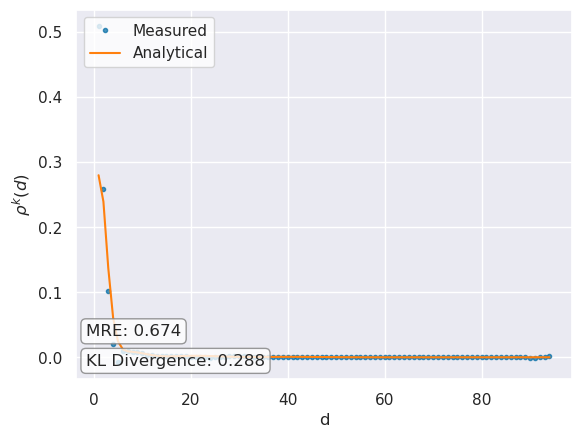

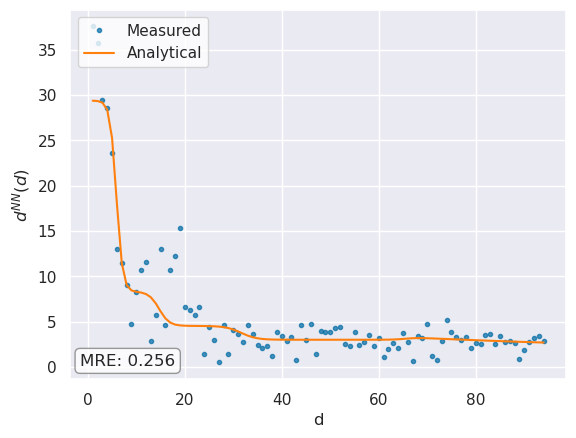

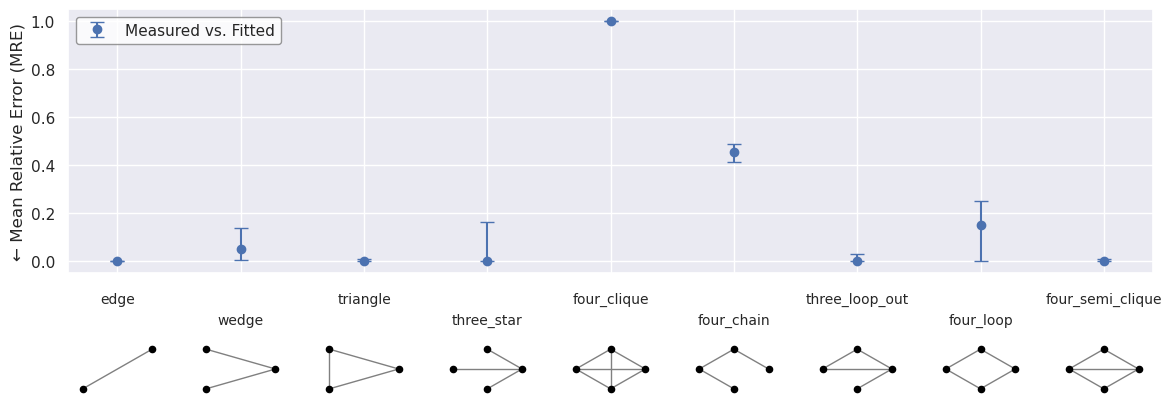

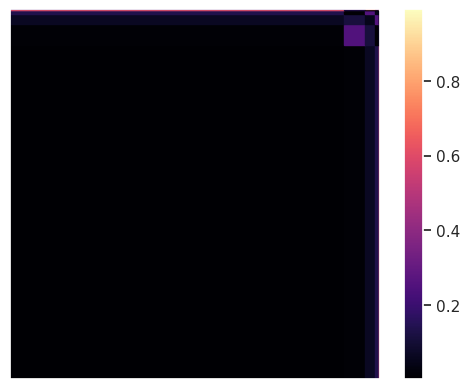

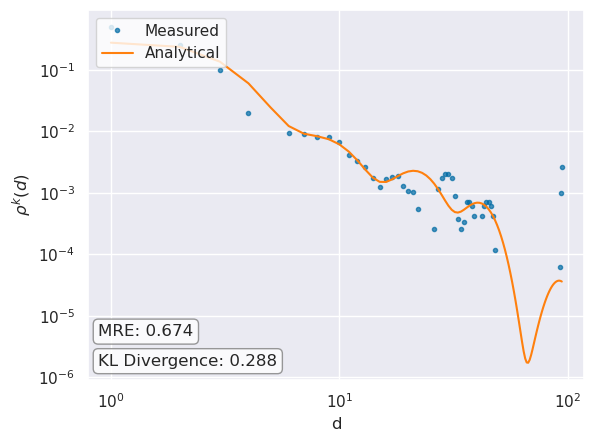

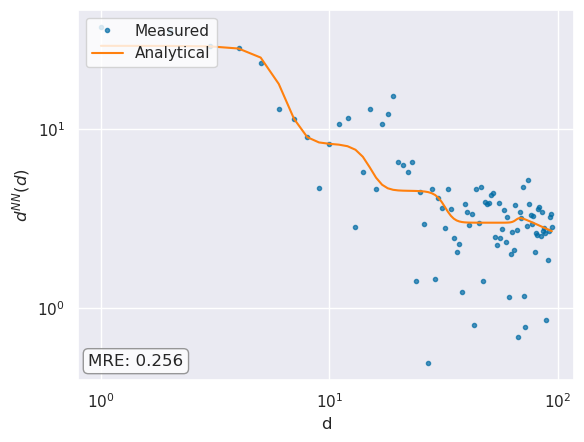

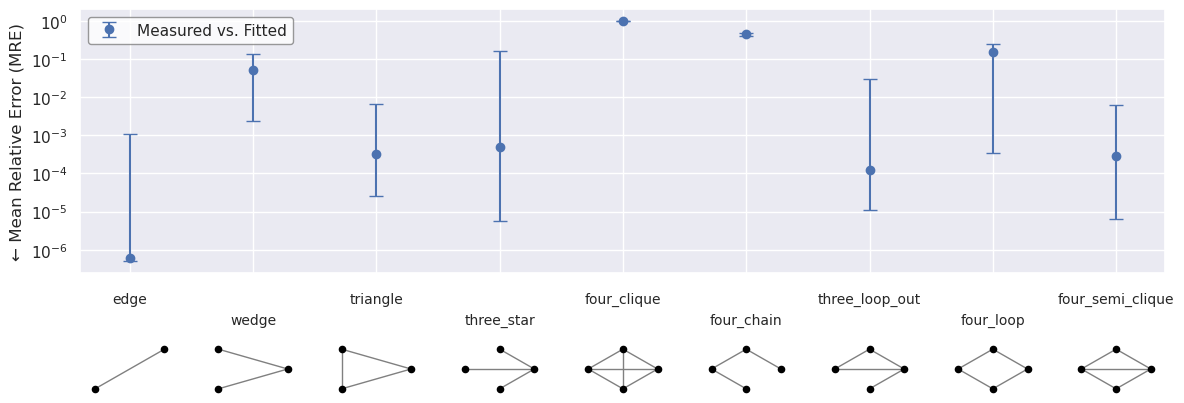

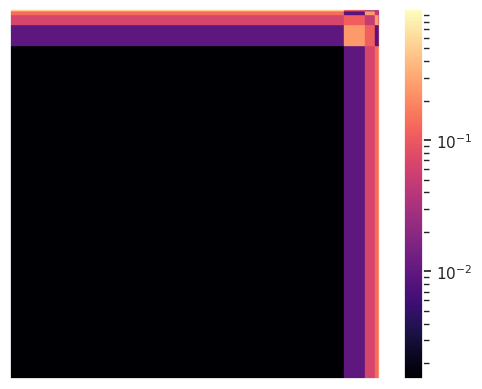

In [53]:
mfnf.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    #filename = "figures/horses_harem_plot.pdf"
)
mfnf.plot_P_l_result(
    log_scale = True,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    #filename = "figures/horses_harem_log_plot.pdf"
)

Energy: 10.471848925062199
KL-divergence: 0.4467550732177676
KLD augumented energy: 8.109219185862552


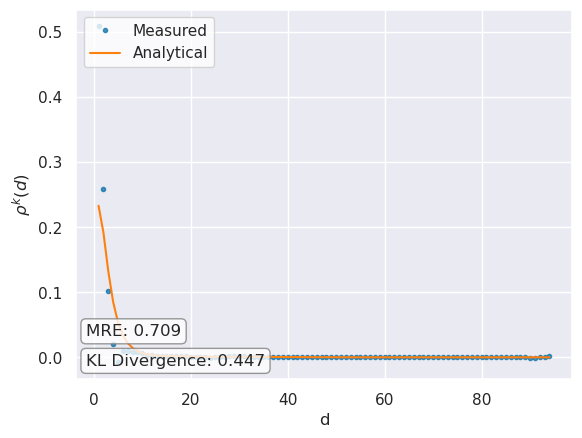

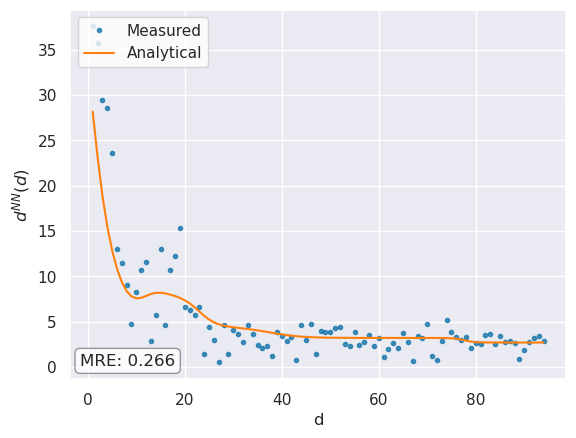

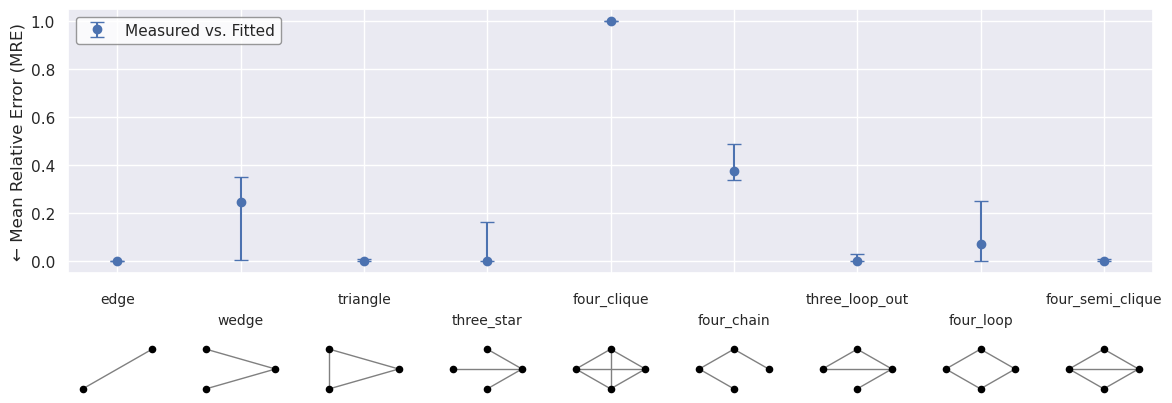

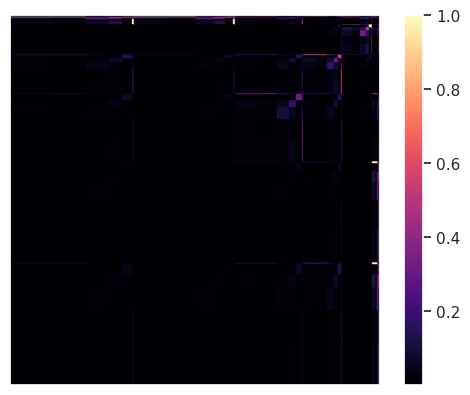

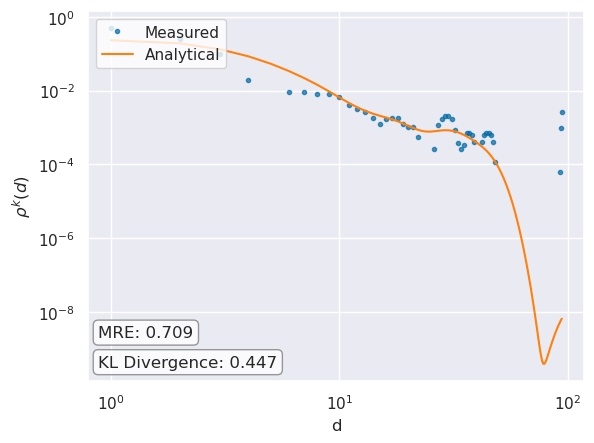

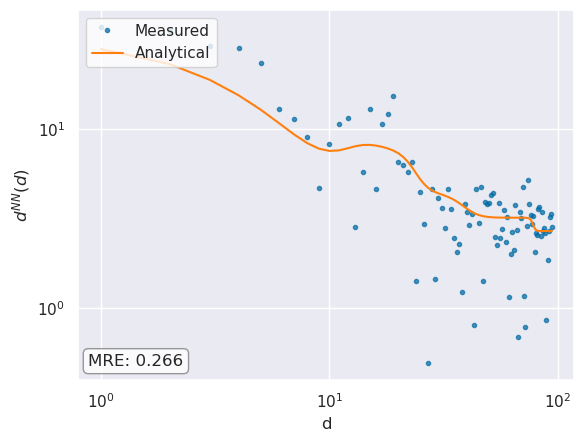

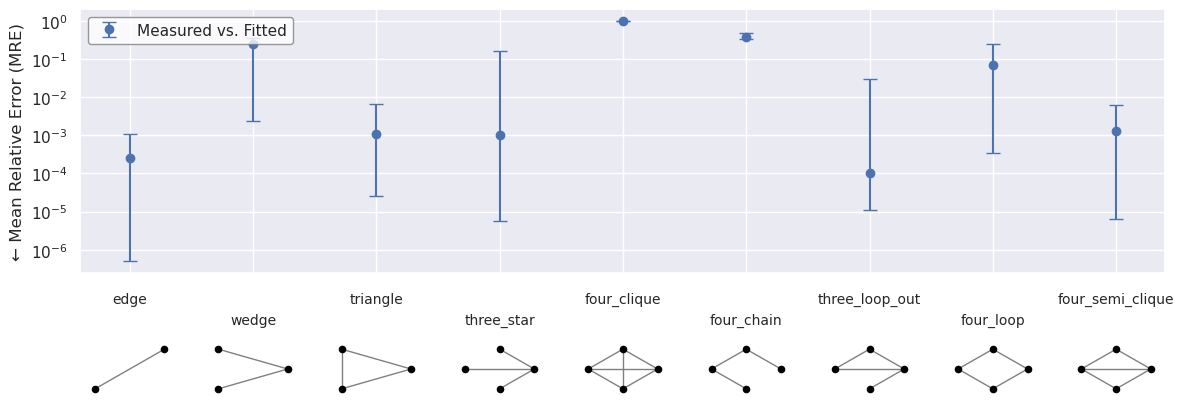

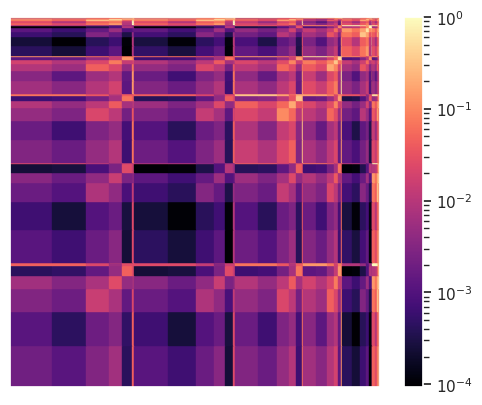

In [54]:
mfnf.find_P_l(7,2, one_shot=True)
mfnf.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    #filename = "figures/horses_harem_plot.pdf"
)
mfnf.plot_P_l_result(
    log_scale = True,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    #filename = "figures/horses_harem_log_plot.pdf"
)

In [ ]:
# We choose 7-2, as the 'best' measures result in k+1-s, that corresponds to networks with 100k nodes, 
# which is too large for this dataset.

# Bootstrap Stability

In [65]:
mfnf.bootstrap_P_l_stability(
    P_init = 'm x m',
    l_init = 'dirichlet',
    verbose = True,
    resample_size = mfnf.population_size,
    ci = 0.95,
    medoid = 'lowest'
)

Gathering statistics (30 runs)...


100%|██████████| 30/30 [1:09:49<00:00, 139.63s/it]

Bootstrapping: Resampling 100 times...


Bootstrapping finished in 0:00:00.317999
Energy = 10.44 (10.44, 10.57)
l = [0.34 (0.30, 0.79), 0.27 (0.07, 0.38), 0.19 (0.05, 0.27), 0.18 (0.02, 0.18), 0.02 (0.01, 0.07), 0.00 (0.00, 0.02), 0.00 (0.00, 0.01)]
P = [
[0.07 (0.00, 0.17), 0.00 (0.00, 0.37), 0.08 (0.00, 0.40), 0.04 (0.00, 0.72), 1.00 (0.00, 1.00), 0.70 (0.00, 1.00), 0.00 (0.00, 1.00)],

[0.00 (0.00, 0.37), 0.00 (0.01, 1.00), 0.06 (0.00, 0.49), 0.00 (0.00, 1.00), 1.00 (0.01, 1.00), 0.05 (0.02, 1.00), 0.77 (0.00, 1.00)],

[0.08 (0.00, 0.40), 0.06 (0.00, 0.49), 0.51 (0.00, 1.00), 0.10 (0.00, 0.90), 0.11 (0.00, 1.00), 0.30 (0.00, 1.00), 0.00 (0.00, 1.00)],

[0.04 (0.00, 0.72), 0.00 (0.00, 1.00), 0.10 (0.00, 0.90), 0.40 (0.03, 1.00), 0.63 (0.00, 0.95), 0.68 (0.00, 1.00), 0.00 (0.00, 1.00)],

[1.00 (0.00, 1.00), 1.00 (0.01, 1.00), 0.11 (0.00, 1.00), 0.63 (0.00, 0.95), 0.57 (0.01, 1.00), 0.50 (0.00, 1.00), 0.00 (0.00, 1.00)],

[0.70 (0.00, 1.00), 0.05 (0.02, 1.00), 0.30 (0.00, 1.00), 0.68 (0.00, 1.00), 0.50 (0.00, 1.00), 0.73 (0.0

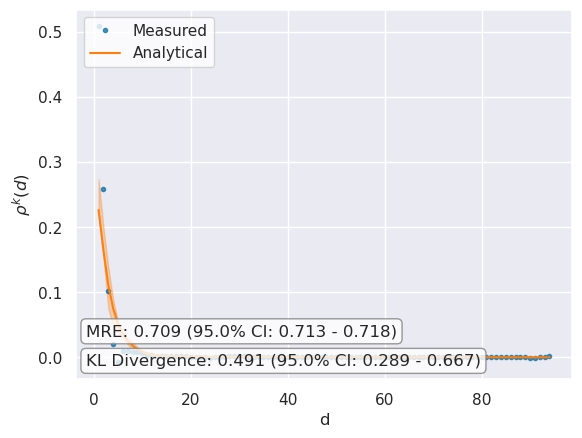

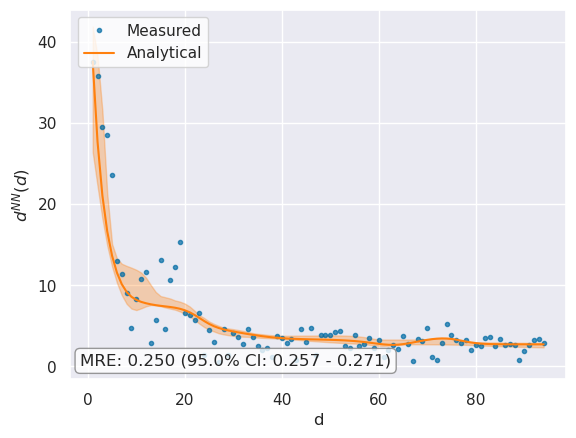

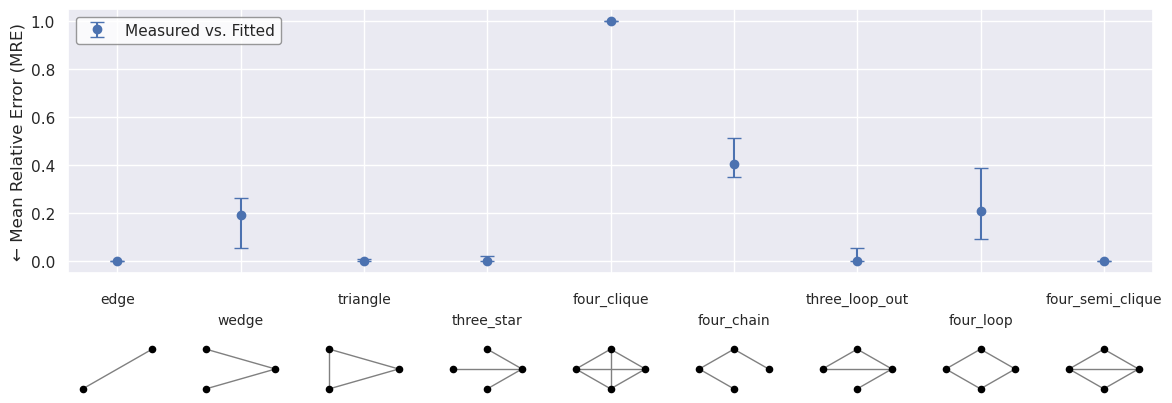

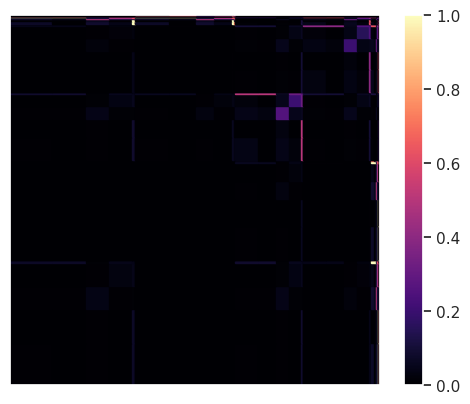

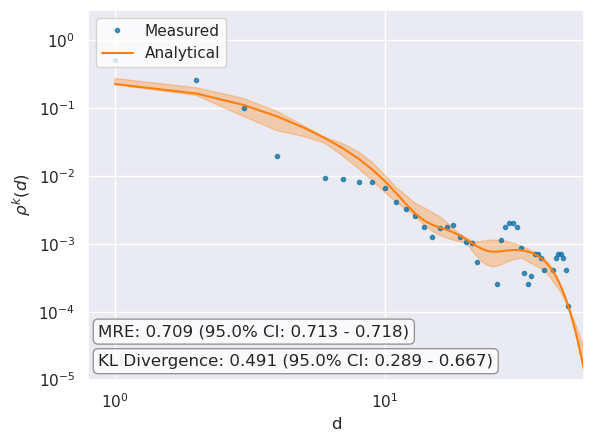

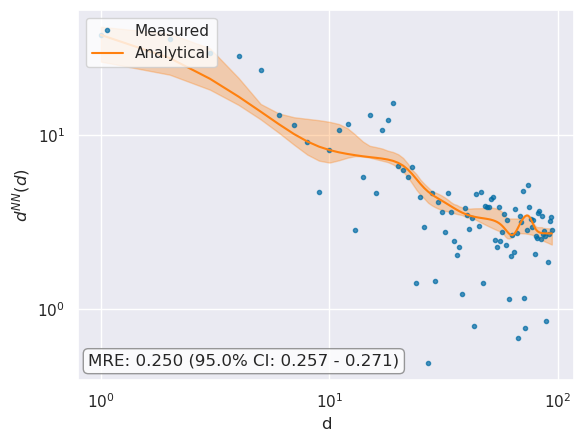

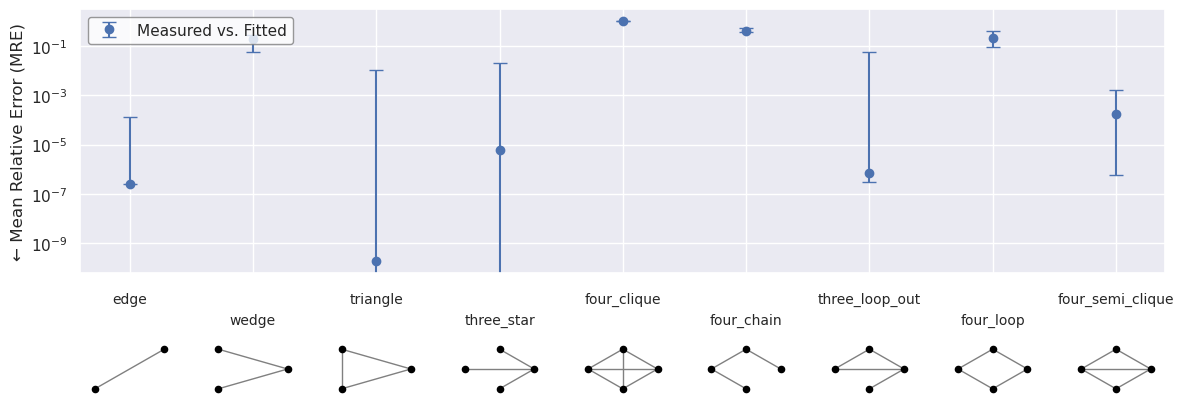

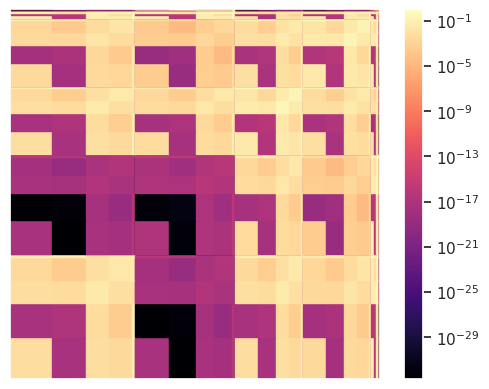

In [66]:
mfnf.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    filename = "figures/dblp_cite_300_nodes_plot.pdf"
)
mfnf.plot_P_l_result(
    log_scale = True,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    xlim = (0,55),
    ylim = (1e-5,0),
    filename = "figures/dblp_cite_300_nodes_log_plot.pdf"
)

In [67]:
mfnf.l

array([0.33896274, 0.26883911, 0.18507521, 0.18369213, 0.02069059,
       0.0020959 , 0.00064431])

In [68]:
mfnf.P

array([[7.12367120e-02, 4.65040859e-17, 8.39395176e-02, 4.29165151e-02,
        1.00000000e+00, 7.03484631e-01, 1.09642710e-16],
       [4.65040859e-17, 1.56867981e-16, 5.66277769e-02, 4.78104048e-03,
        1.00000000e+00, 4.92539964e-02, 7.72137406e-01],
       [8.39395176e-02, 5.66277769e-02, 5.07316754e-01, 9.64004081e-02,
        1.11270149e-01, 3.01436735e-01, 4.30154791e-17],
       [4.29165151e-02, 4.78104048e-03, 9.64004081e-02, 3.95245119e-01,
        6.25252144e-01, 6.84428901e-01, 8.58572749e-17],
       [1.00000000e+00, 1.00000000e+00, 1.11270149e-01, 6.25252144e-01,
        5.65260305e-01, 4.97474220e-01, 4.07761762e-05],
       [7.03484631e-01, 4.92539964e-02, 3.01436735e-01, 6.84428901e-01,
        4.97474220e-01, 7.34966632e-01, 7.59013175e-01],
       [1.09642710e-16, 7.72137406e-01, 4.30154791e-17, 8.58572749e-17,
        4.07761762e-05, 7.59013175e-01, 8.00860823e-01]])

# Scaling the network

In [69]:
P = mfnf.P
l = mfnf.l
k_1k = mfnf.k

In [70]:
starting_avg_degree = 2 * G.number_of_edges() / G.number_of_nodes()

In [71]:
starting_avg_degree

3.1656050955414012

In [72]:
from multifractal_networks.utils.misc import recommend_N_for_k_range

In [73]:
recommend_N_for_k_range(
    P = P,
    l = l,
    k = k_1k,
    avg_degree = 3 * starting_avg_degree,
    k_limit = 4)

{3: 9337, 4: 92843}

In [74]:
print(len(create_cumulative_graph(network_pandas, 20)))

9351


In [75]:
G_20 = create_cumulative_graph(network_pandas, 20)

In [76]:
mfnf_no_fit = MultifractalNetworkFitter(
    G_20,                                   
    motifs = [
        {'name': 'four_chain', 'matrix': np.array([[0, 1, 0, 0],[1, 0, 1, 0],[0, 1, 0, 1],[0, 0, 1, 0]])},
        {'name': 'three_loop_out', 'matrix': np.array([[0, 1, 1, 1],[1, 0, 1, 0],[1, 1, 0, 0],[1, 0, 0, 0]])},
        {'name': 'four_loop', 'matrix': np.array([[0, 1, 0, 1],[1, 0, 1, 0],[0, 1, 0, 1],[1, 0, 1, 0]])},
        {'name': 'four_semi_clique', 'matrix': np.array([[0, 1, 1, 1],[1, 0, 0, 1],[1, 0, 0, 1],[1, 1, 1, 0]])},
    ],
    sampling_ratios = {
        3: 0.01,
        4: 0.0001
    },
    motif_analyzer_args = {'exact': True, 'bootstrap_iters': None, 'ci': None},
    population_size = 100,
    weights = {
        'rho':9,
        'deg_nn':9,
        'motifs':1,
        'edge':9
    }
)

Measuring graph properties...
Degree distribution...
Degree correlations...
Motifs...
Checking compatibility with 4 user-provided motifs.
Adding custom motif 'four_chain'.
Adding custom motif 'three_loop_out'.
Adding custom motif 'four_loop'.
Adding custom motif 'four_semi_clique'.
Counting motifs of size 3... grab a tea or watch a movie, this might take a while.
Motif counting finished in 0:00:03.334982
Counting motifs of size 4... grab a tea or watch a movie, this might take a while.
Motif counting finished in 0:06:57.389301


In [85]:
mfnf_no_fit.motifs

[{'name': 'edge',
  'matrix': array([[0, 1],
         [1, 0]]),
  'size': 2,
  'count': 37292,
  'MRE': 0.16129822365424007},
 {'name': 'wedge',
  'matrix': array([[0, 1, 1],
         [1, 0, 0],
         [1, 0, 0]]),
  'size': 3,
  'count': 1505431,
  'MRE': 0.6299097377082213},
 {'name': 'triangle',
  'matrix': array([[0, 1, 1],
         [1, 0, 1],
         [1, 1, 0]]),
  'size': 3,
  'count': 32310,
  'MRE': 0.81750900066412},
 {'name': 'three_star',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 0, 0],
         [1, 0, 0, 0],
         [1, 0, 0, 0]]),
  'size': 4,
  'count': 125817748,
  'MRE': 0.9098674479312885},
 {'name': 'four_clique',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 1, 1],
         [1, 1, 0, 1],
         [1, 1, 1, 0]]),
  'size': 4,
  'count': 16149,
  'MRE': 0.9947024754953036},
 {'name': 'four_chain',
  'matrix': array([[0, 1, 0, 0],
         [1, 0, 1, 0],
         [0, 1, 0, 1],
         [0, 0, 1, 0]]),
  'size': 4,
  'count': 36489445,
  'MRE': 0.54952119441

In [77]:
mfnf_no_fit.P = P
mfnf_no_fit.l = l
mfnf_no_fit.k = 3

In [78]:
mfnf_no_fit._calculate_metrics()

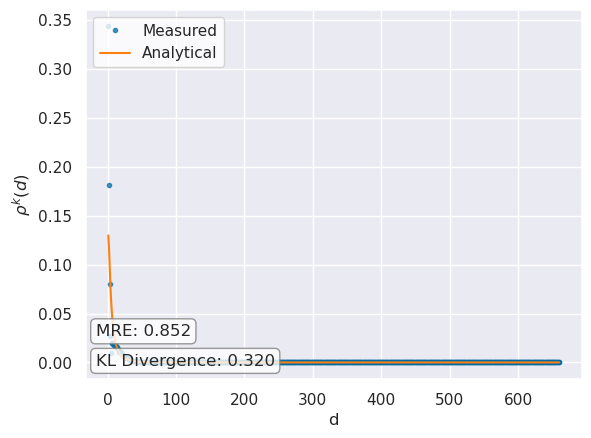

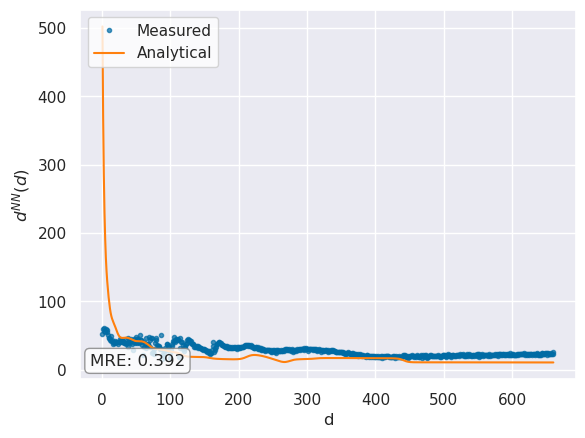

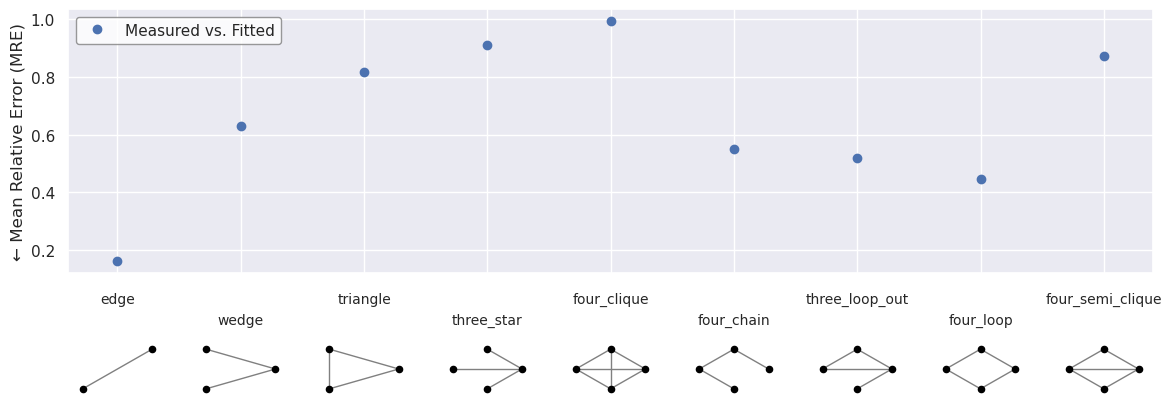

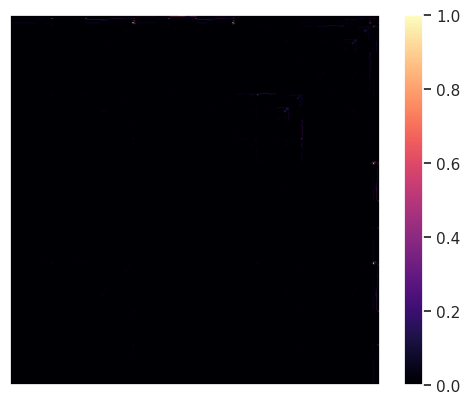

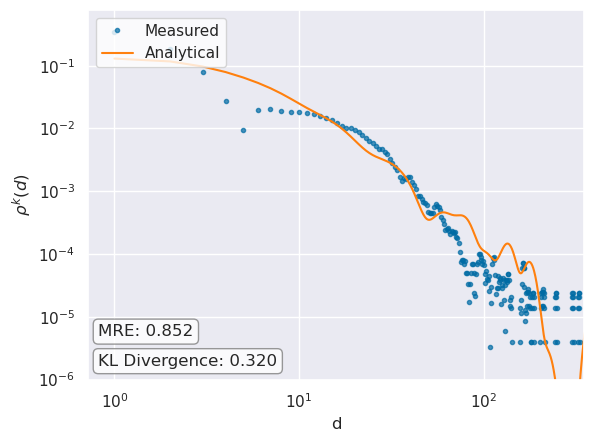

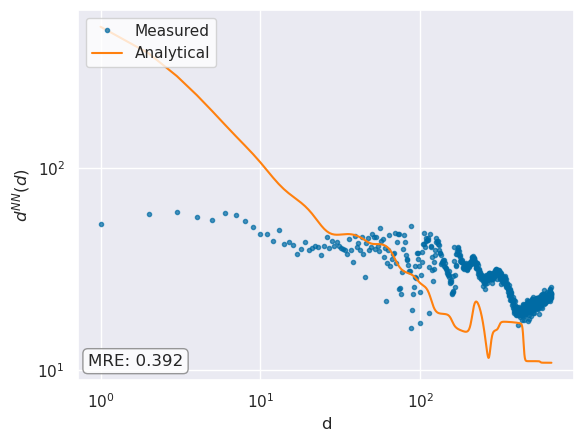

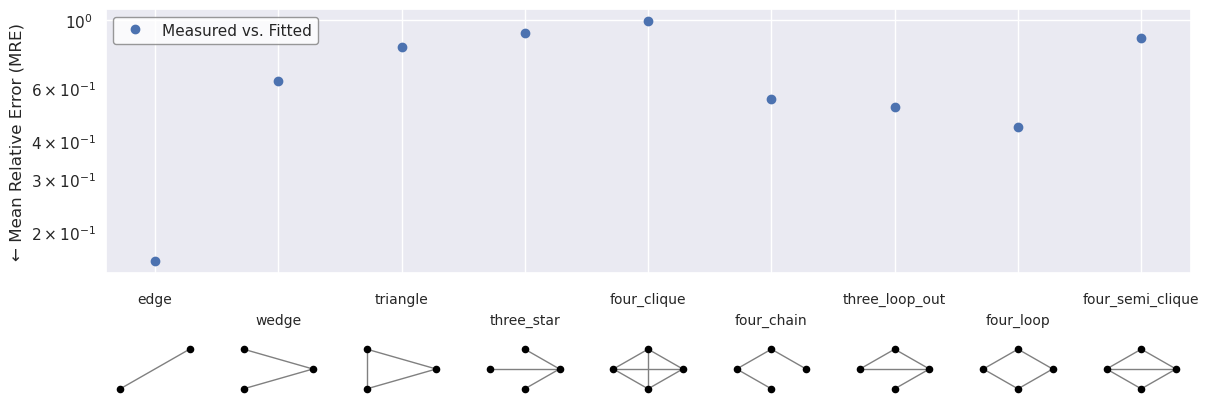

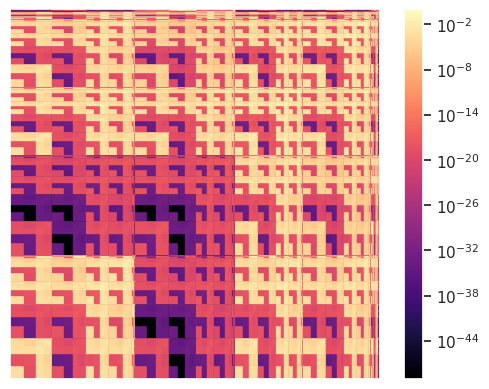

In [88]:
mfnf_no_fit.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    filename = "figures/dblp_cite_9300_nodes_plot.pdf"
)

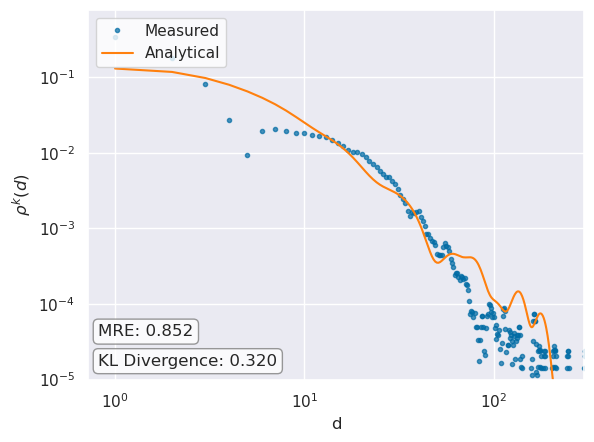

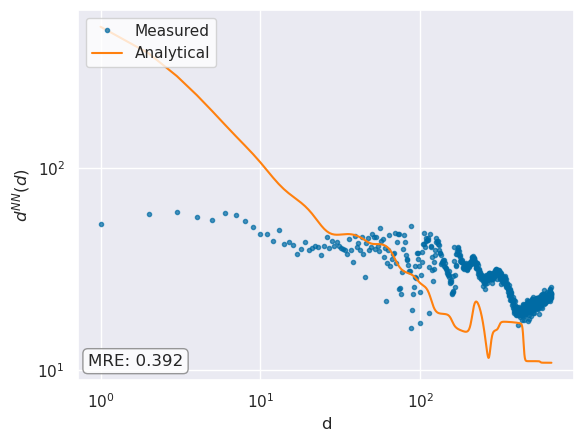

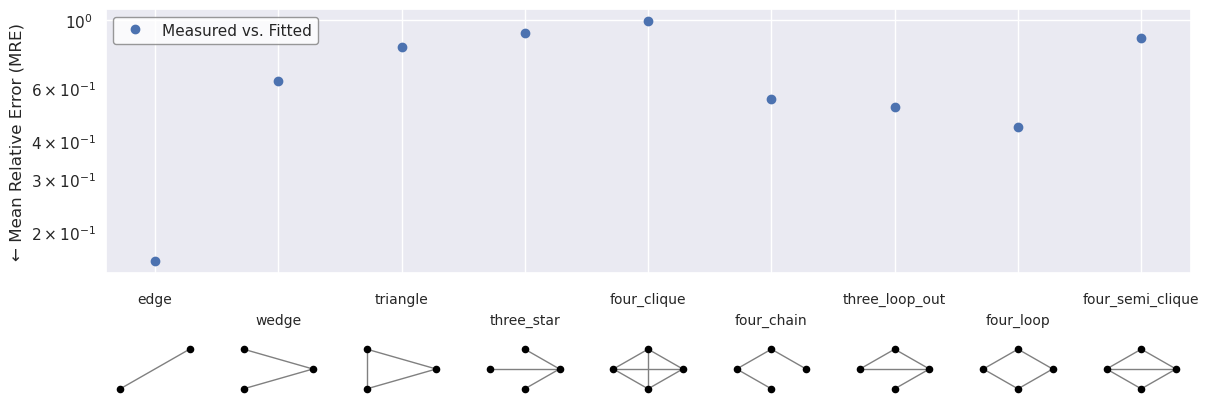

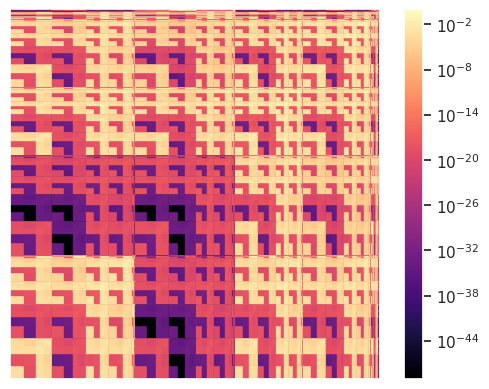

In [89]:
mfnf_no_fit.plot_P_l_result(
    log_scale = True,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    xlim = (0,300),
    ylim = (1e-5,0),
    filename = "figures/dblp_cite_9300_nodes_log_plot.pdf"
)